# Modelo RL de gestão de banca do Libellula

Este notebook implementa o agente de aprendizado por reforço (*reinforcement learning*, ou RL) que dimensiona operações a partir das 29 features já produzidas pelo Libellula. O TFT e o envelope de risco não são treinados aqui: recebemos seu estado combinado em `rl_state.parquet`. A política escolhe exposição, take profit e stop loss contínuos; o simulador mede o resultado no candle real seguinte, e esse resultado orienta o aprendizado.

Toda a implementação está nas células abaixo. Para **treinar**, mantenha `MODE = "train"` e execute as células em ordem. Para **reutilizar um agente salvo**, reinicie o kernel, escolha `MODE = "inference"`, indique o checkpoint e execute novamente em ordem. Nesse segundo modo, o notebook não lê datasets históricos, não cria um otimizador e não executa treinamento. Na etapa 10, `predict_outputs()` recebe uma nova observação de 29 features; o estado corrente da banca pode ser informado por argumentos.

A simulação decide após o fechamento de t, entra na abertura real de t+1 e encerra na mesma vela. Custos permanecem zero. Isso permite verificar o mecanismo, mas não representa uma execução completa de mercado. Com apenas 205 linhas de entrada, resultados favoráveis não demonstram generalização ou segurança financeira. Distinguiremos aquilo que o código verifica das hipóteses que dependem dos módulos anteriores.

### Índice remissivo

- **[1. Carregar e validar dados com alinhamento temporal](#etapa-1)**
  - [1.1 Reprodutibilidade e integridade das entradas](#etapa-1-parte-1)
  - [1.2 Alinhamento do período real seguinte](#etapa-1-parte-2)
- **[2. Definir observações, outputs sagrados e limites operacionais](#etapa-2)**
- **[3. Inicializar banca e estado do ambiente](#etapa-3)**
- **[4. Observar features de t + estado da banca](#etapa-4)**
- **[5. Gerar ação e convertê-la em uma operação válida](#etapa-5)**
- **[6. Executar usando OHLC real de t+1](#etapa-6)**
- **[7. Calcular resultado líquido e atualizar banca](#etapa-7)**
- **[8. Calcular recompensa e registrar a transição](#etapa-8)**
- **[9. Avançar para o próximo período](#etapa-9)**
- **[10. Treinar e avaliar em blocos temporais separados](#etapa-10)**
  - [10.1 Separação temporal e normalização](#etapa-10-parte-1)
  - [10.2 Avaliação sem atualização de pesos](#etapa-10-parte-2)
  - [10.3 Aprendizado ator-crítico](#etapa-10-parte-3)
  - [10.4 Persistência: o que precisa acompanhar os pesos](#etapa-10-parte-4)
  - [10.5 Inferência independente de treinamento](#etapa-10-parte-5)
  - [10.6 Executar o modo escolhido e conferir o recarregamento](#etapa-10-parte-6)
- **[11. Verificação de evolução do modelo](#etapa-11)**
  - [11.1 Métricas e verificações da mecânica](#etapa-11-parte-1)
  - [11.2 Capital em destaque e gráficos de evolução](#etapa-11-parte-2)
  - [11.3 Cada operação e cada atualização de capital](#etapa-11-parte-3)
  - [11.4 Registros salvos e interpretação responsável](#etapa-11-parte-4)


<a id="etapa-1"></a>

## 1. Carregar e validar dados com alinhamento temporal

Para aprender, o agente precisa receber informações disponíveis no momento da decisão e observar suas consequências somente depois de agir. Carregamos duas fontes separadas: o estado com 29 features em t e o histórico OHLC que o simulador usará em t+1. Essa separação impede que o preço futuro seja adicionado acidentalmente à entrada da rede.

Usamos as bibliotecas já presentes no protótipo. Os caminhos partem da pasta do projeto ou de qualquer subpasta sua. Escolher o modo antes de carregar os dados permite reutilizar o checkpoint mesmo sem os arquivos históricos.


In [1]:
from pathlib import Path
import copy
import hashlib
import json
import random

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Normal
import matplotlib.pyplot as plt
from IPython.display import HTML, display

MODE = "train"  # "inference" carrega o agente sem repetir o treinamento.
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "notebooks/modelo_RL_gestao_banca").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Execute dentro da pasta Libellula ou de uma subpasta.")
if MODE not in {"train", "inference"}:
    raise ValueError("MODE deve ser 'train' ou 'inference'.")
STATE_PATH = PROJECT_ROOT / "data/processed/rl_state/rl_state.parquet"
RAW_PATH = PROJECT_ROOT / "data/raw/EUR_USD.csv"
ARTIFACT_DIR = PROJECT_ROOT / "notebooks/modelo_RL_gestao_banca/resultados"
CHECKPOINT_PATH = ARTIFACT_DIR / "agent_checkpoint.pt"


<a id="etapa-1-parte-1"></a>

### 1.1 Reprodutibilidade e integridade das entradas

A inicialização da rede e a amostragem de ações usam números pseudoaleatórios. Uma **semente aleatória** inicializa esses geradores para reduzir diferenças ocasionais entre experimentos sob condições equivalentes. Isso facilita comparações, embora não garanta determinismo absoluto em qualquer hardware ou biblioteca. Fixaremos a semente somente ao treinar; carregar a política não deve reinicializar o experimento.

Antes dos cálculos, verificamos quantidade de colunas, nomes únicos, tipos numéricos, valores finitos e timestamps sem repetição. Não substituímos uma feature ausente por zero: uma rede pode aceitar um número com significado incorreto sem produzir erro.


In [2]:
def validate_features(frame):
    if not isinstance(frame, pd.DataFrame) or frame.empty:
        raise ValueError("O estado deve ser um DataFrame não vazio.")
    if frame.shape[1] != 29 or frame.columns.has_duplicates:
        raise ValueError("São necessárias 29 features com nomes únicos.")
    if not all(isinstance(name, str) for name in frame.columns):
        raise ValueError("Os nomes das features devem ser strings.")
    if not {"pred_return", "cotation(t)"}.issubset(frame.columns):
        raise ValueError("Faltam pred_return ou cotation(t).")
    if frame.index.has_duplicates or frame.index.hasnans:
        raise ValueError("Timestamps duplicados ou ausentes no estado.")
    if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in frame.dtypes):
        raise ValueError("Todas as features devem ser numéricas.")
    if not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError("As features contêm NaN ou infinito.")


def validate_bar(bar):
    values = np.asarray([bar[name] for name in ("Open", "High", "Low", "Close")], dtype=float)
    if not np.isfinite(values).all() or (values <= 0).any():
        raise ValueError("OHLC deve conter quatro preços positivos e finitos.")
    opening, high, low, close = values
    if high < max(opening, close, low) or low > min(opening, close, high):
        raise ValueError("High e Low não contêm todos os preços da vela.")


<a id="etapa-1-parte-2"></a>

### 1.2 Alinhamento do período real seguinte

O candle seguinte é a próxima linha do histórico original, não o dia civil seguinte. Deslocamos o histórico completo antes de selecionar as datas do estado, para que fins de semana e exclusões não transformem t+1 em outra vela. `Price` é o fechamento no arquivo original, cujas datas estão em mês/dia/ano.

Uma abertura diferente do fechamento anterior não é motivo de exclusão. O problema encontrado no dataset é outro: algumas velas têm Open ou Close fora do intervalo entre Low e High da própria vela. Excluímos apenas as transições que usariam essas velas e registramos as datas, sem corrigir preços. Conferimos também se `cotation(t)` coincide com o fechamento original em t.

Esse procedimento protege o alinhamento local do RL. Ele não prova que TFT e risco foram produzidos sem informação futura; essa causalidade deve ser garantida pelos módulos anteriores. Com entradas válidas, podemos definir o espaço de decisão do agente.


In [3]:
def load_market_data(state_path, raw_path):
    features = pd.read_parquet(state_path).copy()
    features.index = pd.DatetimeIndex(pd.to_datetime(features.index), name="timestamp")
    features = features.sort_index()
    validate_features(features)
    raw = pd.read_csv(raw_path)
    raw["Date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y", errors="raise")
    raw = raw.set_index("Date").sort_index()
    if raw.index.has_duplicates or raw.index.hasnans:
        raise ValueError("Timestamps duplicados ou ausentes no OHLC.")
    ohlc = raw[["Open", "High", "Low", "Price"]].rename(columns={"Price": "Close"}).astype(float)
    if not np.isfinite(ohlc.to_numpy()).all() or (ohlc <= 0).any().any():
        raise ValueError("Há preços ausentes, infinitos ou não positivos.")
    if not features.index.isin(ohlc.index).all():
        raise ValueError("Há timestamps do estado ausentes no histórico original.")
    np.testing.assert_allclose(features["cotation(t)"], ohlc.loc[features.index, "Close"], rtol=1e-7, atol=1e-8)
    valid = (ohlc.High >= ohlc.max(axis=1)) & (ohlc.Low <= ohlc.min(axis=1))
    following = ohlc.shift(-1)
    following["execution_time"] = pd.Series(ohlc.index, index=ohlc.index).shift(-1)
    following["valid_ohlc"] = valid.shift(-1)
    market = following.loc[features.index].copy()
    if market.isna().any().any():
        raise ValueError("Existe uma observação sem candle real seguinte.")
    if not (market.execution_time.to_numpy() > features.index.to_numpy()).all():
        raise ValueError("Execução deve ocorrer estritamente depois da decisão.")
    excluded = market.loc[~market.valid_ohlc.astype(bool), ["execution_time"]].copy()
    keep = market.valid_ohlc.astype(bool)
    features, market = features.loc[keep].copy(), market.loc[keep].copy()
    validate_features(features)
    return features, market.drop(columns="valid_ohlc"), excluded


if MODE == "train":
    features, market, excluded = load_market_data(STATE_PATH, RAW_PATH)
    print(f"Estado utilizável: {features.shape[0]} linhas e {features.shape[1]} features.")
    display(excluded.rename_axis("decisao_excluida"))
    display(market[["execution_time"]].head(3))


Estado utilizável: 203 linhas e 29 features.


,execution_time
decisao_excluida,
2025-01-06,2025-01-07
2025-04-18,2025-04-21


,execution_time
timestamp,
2024-07-18,2024-07-19
2024-07-19,2024-07-22
2024-07-22,2024-07-23


<a id="etapa-2"></a>

## 2. Definir observações, outputs sagrados e limites operacionais

Em RL, o **estado** descreve a situação em que uma decisão será tomada. A entrada externa continua sendo o vetor de 29 features. Acrescentamos internamente quatro valores da banca: capital relativo ao inicial, drawdown, exposição atual e indicador de posição aberta. A rede recebe 33 números. Como cada operação termina na mesma vela, os dois últimos são zero nos instantes de decisão.

A **ação** é a escolha da política. Mantemos três variáveis latentes contínuas, transformadas por `sacred_outputs()` em `[direção, exposição, distância_TP, distância_SL]`. A direção é o sinal de `pred_return`, e não uma nova decisão do RL. Exposição é fração da banca entre zero e um; distâncias são frações do preço de entrada. Níveis abaixo da entrada exigem distância menor que um para preservar preços positivos. Níveis acima não recebem teto fixo. Não introduzimos catálogo, grade de escolhas ou alavancagem.

Os parâmetros abaixo controlam o aprendizado, não as escolhas operacionais. São heurísticas do protótipo: 80 episódios repetem o pequeno histórico; a taxa 0,001 controla o tamanho das atualizações; o desconto 0,99 dá mais peso a resultados próximos; e a entropia 0,01 incentiva exploração. Eles não foram empiricamente validados como superiores a alternativas.


In [4]:
CONFIG = {
    "initial_capital": 100.0,
    "episodes": 80,
    "learning_rate": 0.001,
    "gamma": 0.99,
    "entropy_weight": 0.01,
    "drawdown_penalty": 1.0,
    "seed": 42,
}


def validate_config(config):
    numbers = [config[key] for key in ("initial_capital", "learning_rate", "gamma", "entropy_weight", "drawdown_penalty")]
    if not np.isfinite(np.asarray(numbers, dtype=float)).all():
        raise ValueError("Configuração contém valores não finitos.")
    if config["initial_capital"] <= 0 or config["learning_rate"] <= 0:
        raise ValueError("Capital inicial e taxa de aprendizado devem ser positivos.")
    if not isinstance(config["episodes"], int) or config["episodes"] < 1:
        raise ValueError("episodes deve ser inteiro positivo.")
    if not 0 <= config["gamma"] <= 1 or min(config["entropy_weight"], config["drawdown_penalty"]) < 0:
        raise ValueError("Desconto deve estar em [0, 1]; entropia e penalização não podem ser negativas.")


validate_config(CONFIG)


O coeficiente de drawdown passa de zero para **1,0**. A fórmula é preservada, mas a penalização deixa de estar desativada: um aumento de um ponto percentual no drawdown desconta 0,01 da recompensa. É um peso inicial explícito, não uma garantia de segurança nem uma calibração empírica. Na etapa 8 explicaremos o cálculo; na etapa 10 escolheremos os pesos pela recompensa de validação, alinhando seleção e treinamento.

A logística normalmente gera exposição estritamente entre zero e um. A política pode aproximar-se de zero, mas não possui uma ação categórica para não operar. Uma previsão exatamente nula continua produzindo o vetor nulo. Com o contrato definido, podemos estabelecer como a banca começa cada simulação.


<a id="etapa-3"></a>

## 3. Inicializar banca e estado do ambiente

Um **episódio** é uma passagem pelo bloco histórico da simulação. Dentro dele, ganhos e perdas são cumulativos: o capital atualizado de uma operação financia a próxima. No episódio seguinte, voltamos ao capital inicial e preservamos apenas o aprendizado da rede. Somar saldos de episódios trataria a repetição do mesmo histórico como se fosse continuação real do mercado.

O estado da banca guarda capital inicial, capital corrente e maior valor observado, chamado pico. O pico permite medir o **drawdown**, a queda proporcional em relação ao melhor patrimônio alcançado. A função cria uma banca independente e valida seus valores. O ambiente completo será definido na etapa 9, depois das funções de observação, execução e recompensa.


In [5]:
def new_bank(initial_capital, capital=None, peak=None):
    initial = float(initial_capital)
    current = initial if capital is None else float(capital)
    highest = max(initial, current) if peak is None else float(peak)
    if not np.isfinite([initial, current, highest]).all():
        raise ValueError("Os valores da banca devem ser finitos.")
    if initial <= 0 or current <= 0 or highest < max(initial, current):
        raise ValueError("Capital deve ser positivo e pico deve conter capital atual e inicial.")
    return {"initial_capital": initial, "capital": current, "peak": highest}


<a id="etapa-4"></a>

## 4. Observar features de t + estado da banca

A **observação** é o vetor numérico entregue à rede. Features com escalas diferentes podem dificultar o aprendizado. Usamos normalização pela média e pelo desvio-padrão: para cada feature calculamos `(valor − média) / desvio`. Essas estatísticas serão ajustadas exclusivamente no treino e congeladas na validação, teste e inferência. Um desvio praticamente nulo é substituído por um para evitar divisão por zero.

A função recebe uma linha de mercado e a banca. Não recebe OHLC futuro nem acessa arquivos, podendo servir tanto ao ambiente quanto à inferência em sessão nova. As quatro variáveis da banca são acrescentadas após normalizar as 29 features; sua interpretação deve ser idêntica ao carregar o modelo. A observação preparada aqui será consumida pela política seguinte.


In [6]:
def build_observation(feature_values, mean, scale, bank):
    values = np.asarray(feature_values, dtype=float)
    mean = np.asarray(mean, dtype=float)
    scale = np.asarray(scale, dtype=float)
    if any(array.shape != (29,) for array in (values, mean, scale)):
        raise ValueError("Features, média e desvio devem ter dimensão (29,).")
    if not all(np.isfinite(array).all() for array in (values, mean, scale)) or (scale <= 0).any():
        raise ValueError("Normalização exige valores finitos e desvios positivos.")
    bank_values = [bank["capital"] / bank["initial_capital"],
                   1.0 - bank["capital"] / bank["peak"], 0.0, 0.0]
    observation = np.concatenate(((values - mean) / scale, bank_values)).astype(np.float32)
    if not np.isfinite(observation).all():
        raise ValueError("Observação fora da faixa numérica da rede.")
    return observation


<a id="etapa-5"></a>

## 5. Gerar ação e convertê-la em uma operação válida

A **política** é a regra aprendida que relaciona observações a ações. Preservamos a rede ator-crítico: duas camadas compartilhadas, com 64 e 32 unidades, alimentam uma saída que propõe três variáveis contínuas e outra que estima retorno futuro. O ator propõe a ação; o crítico estima a qualidade do estado para auxiliar o aprendizado.

Durante o treino, amostramos valores de três distribuições Normais independentes, com médias fornecidas pela rede e dispersões aprendidas. Essa variação é a **exploração**: experimentar decisões permite observar consequências diferentes. Na avaliação e inferência usamos as médias, sem sorteios. O viés inicial de −5 nas distâncias coloca as primeiras saídas próximas da entrada; ele é treinável e não restringe valores futuros.

A ação latente ainda não é uma ordem. `sacred_outputs()` mantém as transformações anteriores: logística para valores limitados e softplus para distâncias positivas sem teto. A proteção numérica junto de zero e um evita preço zero por arredondamento. Preservamos significado, unidades e intervalos dos quatro outputs.


In [7]:
class ActorCritic(nn.Module):
    def __init__(self, input_size=33, hidden_sizes=(64, 32), action_size=3):
        super().__init__()
        if input_size != 33 or tuple(hidden_sizes) != (64, 32) or action_size != 3:
            raise ValueError("Arquitetura incompatível com o contrato atual.")
        self.body = nn.Sequential(nn.Linear(input_size, 64), nn.Tanh(), nn.Linear(64, 32), nn.Tanh())
        self.policy = nn.Linear(32, action_size)
        self.log_std = nn.Parameter(torch.full((action_size,), -0.5))
        self.value = nn.Linear(32, 1)
        with torch.no_grad():
            self.policy.bias.copy_(torch.tensor([0.0, -5.0, -5.0]))

    def forward(self, observation):
        hidden = self.body(observation)
        return self.policy(hidden), self.value(hidden).squeeze(-1)

    def distribution(self, location):
        return Normal(location, self.log_std.exp())


In [8]:
def sacred_outputs(action, predicted_return):
    action = np.asarray(action, dtype=float)
    if action.shape != (3,) or not np.isfinite(action).all():
        raise ValueError('A ação deve conter três valores reais finitos.')
    direction = int(np.sign(predicted_return))
    if direction == 0:
        return np.zeros(4, dtype=float)
    bounded = np.exp(-np.logaddexp(0.0, -action))
    positive = np.logaddexp(0.0, action)
    # Proteção contra preço zero por arredondamento de ponto flutuante.
    below = np.clip(bounded, np.finfo(float).eps, 1.0 - np.finfo(float).eps)
    above = np.maximum(positive, np.finfo(float).eps)
    exposure = bounded[0]
    tp = above[1] if direction > 0 else below[1]
    sl = below[2] if direction > 0 else above[2]
    return np.array([direction, exposure, tp, sl], dtype=float)


A inferência emite distâncias relativas. Os preços absolutos de TP e SL só podem ser calculados quando a entrada estiver disponível. O agente não precisa conhecer a abertura futura para decidir; o simulador converte distâncias em preços no momento da execução. A próxima etapa define essa conversão.


<a id="etapa-6"></a>

## 6. Executar usando OHLC real de t+1

A decisão usa o estado após o fechamento de t, e a entrada acontece no **Open real de t+1**. Para compras, TP fica acima e SL abaixo; para vendas, os sentidos se invertem. High e Low mostram se os níveis foram tocados; Close encerra a operação quando nenhum nível foi atingido. Nenhuma posição é carregada para outra vela.

OHLC informa abertura, extremos e fechamento, mas não reconstrói a sequência intrabar. Se TP e SL forem atingidos, consideramos SL primeiro: uma aproximação conservadora, não uma afirmação sobre a ordem real dos negócios. Toque exato conta como execução. Os níveis nascem na abertura; portanto não simulamos gaps de posições herdadas.

Recusamos preços incoerentes, valores não finitos e níveis sem representação numérica válida. Isso acrescenta tratamento de erro sem alterar as regras. A saída do simulador descreve entrada, níveis, saída e motivo; o resultado monetário será calculado na etapa 7.


In [9]:
def execute_trade(outputs, bar):
    outputs = np.asarray(outputs, dtype=float)
    if outputs.shape != (4,) or not np.isfinite(outputs).all():
        raise ValueError("Outputs devem conter quatro valores finitos.")
    direction, exposure, tp_distance, sl_distance = outputs
    if direction not in (-1, 0, 1) or not 0 <= exposure <= 1:
        raise ValueError("Direção ou exposição inválida.")
    validate_bar(bar)
    entry = float(bar["Open"])
    if direction == 0 or exposure == 0:
        return dict(entry=entry, exit=entry, tp=None, sl=None, reason="FORA")
    if min(tp_distance, sl_distance) <= 0:
        raise ValueError("Distâncias de saída devem ser positivas.")
    tp = entry * (1 + direction * tp_distance)
    sl = entry * (1 - direction * sl_distance)
    if not np.isfinite([tp, sl]).all() or min(tp, sl) <= 0:
        raise ValueError("Os níveis não resultam em preços positivos e finitos.")
    if direction * (tp - entry) <= 0 or direction * (sl - entry) >= 0:
        raise ValueError("Níveis devem estar em lados opostos da entrada.")
    tp_hit = bar["High"] >= tp if direction > 0 else bar["Low"] <= tp
    sl_hit = bar["Low"] <= sl if direction > 0 else bar["High"] >= sl
    if sl_hit:
        exit_price, reason = sl, "SL_AMBOS" if tp_hit else "SL"
    elif tp_hit:
        exit_price, reason = tp, "TP"
    else:
        exit_price, reason = float(bar["Close"]), "CLOSE"
    return dict(entry=entry, exit=float(exit_price), tp=float(tp), sl=float(sl), reason=reason)


<a id="etapa-7"></a>

## 7. Calcular resultado líquido e atualizar banca

O tamanho financeiro da posição é capital disponível multiplicado pela exposição. Dividindo esse valor pela entrada, obtemos a quantidade negociada. O resultado é `direção × quantidade × (saída − entrada)`: +1 representa compra, e −1 representa venda. O próximo capital é o anterior acrescido do resultado líquido. A alocação não é somada ao patrimônio como lucro.

Custos continuam zero. Vendas são sintéticas: não modelamos empréstimo, margem ou liquidação forçada. Mesmo sem exposição acima de 100%, uma venda pode perder mais que a banca se o preço subir suficientemente. O contrato atual não impede isso. Preservamos o resultado negativo e encerramos o episódio, em vez de truncar o prejuízo artificialmente.

A calculadora é pura: devolve resultado e capital seguinte sem modificar a banca. O ambiente aplicará essa atualização na etapa 9, depois de calcular a recompensa. Separar cálculo e mutação permite conferir a contabilização isoladamente.


In [10]:
def settle_trade(capital, outputs, execution):
    capital = float(capital)
    if not np.isfinite(capital) or capital <= 0:
        raise ValueError("Uma operação deve começar com capital positivo e finito.")
    direction, exposure, _, _ = outputs
    quantity = capital * exposure / execution["entry"] if direction else 0.0
    gross = direction * quantity * (execution["exit"] - execution["entry"])
    costs = 0.0
    net = float(gross - costs)
    capital_after = float(capital + net)
    if not np.isfinite([quantity, net, capital_after]).all():
        raise ValueError("Resultado financeiro não finito.")
    return dict(quantity=float(quantity), gross_pnl=float(gross), costs=costs,
                net_pnl=net, capital_after=capital_after)


<a id="etapa-8"></a>

## 8. Calcular recompensa e registrar a transição

A **recompensa** ensina a política; não é um segundo crédito à banca. O resultado financeiro modifica o patrimônio uma única vez. Mantemos a fórmula `resultado líquido / capital anterior − coeficiente × aumento positivo do drawdown`. O primeiro termo mede retorno proporcional; o segundo desconta o agravamento da queda em relação ao pico. Uma recuperação que reduza o drawdown não recebe punição adicional.

Se a banca passa de 100 para 99 e o pico é 100, o retorno é −0,01 e o drawdown aumenta 0,01. Com coeficiente 1, a recompensa é −0,02, mas a perda financeira continua sendo apenas 1. Isso dá peso explícito à segurança sem inventar outputs. O coeficiente pode ser estudado na validação; ajustá-lo após olhar o teste compromete a independência desse teste.

A função devolve recompensa, drawdown e novo pico. O ambiente reunirá esses valores com ação e resultado para registrar a **transição**, a passagem de uma situação à seguinte. Esse registro permite auditar decisões, em vez de observar apenas o saldo final.


In [11]:
def calculate_reward(capital_before, capital_after, peak_before, penalty):
    values = [capital_before, capital_after, peak_before, penalty]
    if not np.isfinite(values).all() or capital_before <= 0 or peak_before < capital_before or penalty < 0:
        raise ValueError("Valores inválidos para calcular a recompensa.")
    previous_drawdown = 1.0 - capital_before / peak_before
    peak_after = max(peak_before, capital_after)
    drawdown = 1.0 - capital_after / peak_after
    reward = (capital_after - capital_before) / capital_before
    reward -= penalty * max(0.0, drawdown - previous_drawdown)
    return float(reward), float(drawdown), float(peak_after)


<a id="etapa-9"></a>

## 9. Avançar para o próximo período

Reunimos agora as responsabilidades anteriores em um ambiente. Ele guarda as features, as velas correspondentes e a banca. `reset()` inicia um episódio; `step()` recebe uma ação, calcula os outputs, simula a operação em t+1, calcula resultado e recompensa, atualiza a banca e avança uma linha. Cada cálculo permanece na função já explicada, sem distribuir código por módulos externos.

O episódio termina ao consumir o bloco ou quando o capital fica não positivo. A observação terminal é zero e não será usada para abrir outra posição. Uma ação posterior é recusada até reinicializar o ambiente. Validamos dimensões e cronologia para evitar associar a decisão a outra vela. A observação consulta apenas features correntes e banca; o OHLC seguinte fica restrito à execução.


In [12]:
class BankEnvironment:
    def __init__(self, features, market, mean, scale, initial_capital, drawdown_penalty):
        validate_features(features)
        if not features.index.is_monotonic_increasing or not features.index.equals(market.index):
            raise ValueError("Features e mercado precisam do mesmo índice temporal crescente.")
        if not (pd.to_datetime(market["execution_time"]).to_numpy() > features.index.to_numpy()).all():
            raise ValueError("Execução deve ser posterior à decisão.")
        for _, bar in market.iterrows():
            validate_bar(bar)
        if not np.isfinite(drawdown_penalty) or drawdown_penalty < 0:
            raise ValueError("Penalização de drawdown inválida.")
        self.features, self.market = features.copy(), market.copy()
        self.mean = np.asarray(mean, dtype=float).copy()
        self.scale = np.asarray(scale, dtype=float).copy()
        self.initial_capital = float(initial_capital)
        self.drawdown_penalty = float(drawdown_penalty)
        self.reset()

    def reset(self):
        self.bank = new_bank(self.initial_capital)
        self.index = 0
        self.history = []
        self.done = False
        return self.observe()

    def observe(self):
        if self.done:
            return np.zeros(33, dtype=np.float32)
        row = self.features.iloc[self.index].to_numpy(dtype=float)
        return build_observation(row, self.mean, self.scale, self.bank)

    def step(self, action):
        if self.done:
            raise RuntimeError("Episódio encerrado; use reset() antes de agir.")
        current = self.features.iloc[self.index]
        before, peak_before = self.bank["capital"], self.bank["peak"]
        outputs = sacred_outputs(action, current["pred_return"])
        execution = execute_trade(outputs, self.market.iloc[self.index])
        settlement = settle_trade(before, outputs, execution)
        reward, drawdown, peak = calculate_reward(
            before, settlement["capital_after"], peak_before, self.drawdown_penalty)
        self.bank.update(capital=settlement["capital_after"], peak=peak)
        record = dict(
            t=self.features.index[self.index], execution_time=self.market.iloc[self.index]["execution_time"],
            action=np.asarray(action, dtype=float).tolist(), direction=int(outputs[0]), exposure=float(outputs[1]),
            tp_distance=float(outputs[2]), sl_distance=float(outputs[3]), capital_before=before,
            drawdown=drawdown, reward=reward, **execution, **settlement)
        self.history.append(record)
        self.index += 1
        self.done = self.index == len(self.features) or self.bank["capital"] <= 0
        return self.observe(), reward, self.done, record


<a id="etapa-10"></a>

## 10. Treinar e avaliar em blocos temporais separados

Distinguimos três operações: **treinar** modifica parâmetros; **persistir** salva agente e pré-processamento; **inferir** aplica o agente salvo a uma nova observação. As funções são definidas em qualquer modo, mas apenas a chamada de treinamento depende de `MODE == "train"`. Uma sessão nova pode carregar o checkpoint sem ler histórico nem repetir episódios.

No treino, a rede aprende com experiências. Na validação, medimos a política após cada episódio e escolhemos pesos, sem aprender com essas operações por gradientes. O teste é reservado à política selecionada. Mantemos a separação cronológica 70%/15%/15% e removemos da borda anterior transições cuja execução alcance o início do bloco seguinte. Uma vela não pode atravessar a fronteira entre blocos.


<a id="etapa-10-parte-1"></a>

### 10.1 Separação temporal e normalização

Média e desvio são calculados após retirar transições de borda e usam apenas o treino. Validação e teste não podem alterar essas estatísticas. O normalizador fica congelado entre episódios e acompanha a rede salva, preservando o significado numérico das entradas.

O teste mede desempenho condicionado às features recebidas. Não certifica sozinho a independência de todo o Libellula: as previsões atuais vieram da validação do TFT, e a causalidade das features de risco continua sendo responsabilidade anterior. A função abaixo devolve os três blocos e as estatísticas de treino.


In [13]:
def temporal_split(features, market):
    if len(features) < 20:
        raise ValueError("São necessárias ao menos 20 observações para os três blocos.")
    first, second = int(len(features) * 0.70), int(len(features) * 0.85)
    indices = {"train": features.index[:first], "validation": features.index[first:second],
               "test": features.index[second:]}
    for previous, following in (("train", "validation"), ("validation", "test")):
        index = indices[previous]
        indices[previous] = index[market.loc[index, "execution_time"].to_numpy() < indices[following][0]]
    if any(len(index) == 0 for index in indices.values()):
        raise ValueError("Um bloco ficou vazio após separar as bordas.")
    train = features.loc[indices["train"]]
    mean = train.mean().to_numpy(dtype=float)
    scale = train.std(ddof=0).to_numpy(dtype=float)
    scale = np.where(scale < 1e-12, 1.0, scale)
    return indices, mean, scale


<a id="etapa-10-parte-2"></a>

### 10.2 Avaliação sem atualização de pesos

A avaliação cria uma banca nova e percorre o bloco com a média da política, sem sorteio ou gradientes. Features, normalizador e configuração são argumentos explícitos; a função não depende de objetos deixados por uma execução anterior.

Preservamos os dois comparadores: ficar fora e operar com exposição fixa de 25%, TP de 0,5% e SL de 0,5%, na direção do TFT. Corrigimos uma pequena diferença matemática do comparador anterior: logística e softplus exigem inversas diferentes para reproduzir a mesma distância em compras e vendas. Esses valores pertencem somente ao comparador e não limitam o agente.


In [14]:
def evaluate_policy(model, features, market, mean, scale, config, baseline=None):
    if baseline not in (None, "flat", "fixed"):
        raise ValueError("Comparador desconhecido.")
    environment = BankEnvironment(features, market, mean, scale,
                                  config["initial_capital"], config["drawdown_penalty"])
    observation = environment.reset()
    model.eval()
    with torch.no_grad():
        while not environment.done:
            location, _ = model(torch.as_tensor(observation))
            action = location.numpy()
            if baseline == "flat":
                action = np.array([-1000.0, -5.0, -5.0])
            elif baseline == "fixed":
                direction = np.sign(features.iloc[environment.index]["pred_return"])
                bounded_distance = np.log(0.005 / 0.995)
                unbounded_distance = np.log(np.expm1(0.005))
                tp, sl = ((unbounded_distance, bounded_distance) if direction > 0
                          else (bounded_distance, unbounded_distance))
                action = np.array([np.log(0.25 / 0.75), tp, sl])
            observation, _, _, _ = environment.step(action)
    return pd.DataFrame(environment.history)


<a id="etapa-10-parte-3"></a>

### 10.3 Aprendizado ator-crítico

Após cada episódio, calculamos para cada decisão a soma das recompensas futuras, descontadas por `gamma`. Esse retorno é o alvo do crítico. A **vantagem** é retorno observado menos valor estimado: uma ação melhor que a expectativa deve ficar mais provável, e uma pior deve ficar menos provável. A política aprende pela probabilidade da ação latente amostrada. Como a transformação operacional é fixa, não precisamos derivar o simulador nem os preços.

A perda combina objetivo da política, erro quadrático do crítico e entropia da distribuição latente. Entropia maior incentiva exploração, mas não mede segurança diretamente. Adam atualiza os parâmetros uma vez por episódio, e limitamos a norma dos gradientes a um para reduzir instabilidade. São os mesmos componentes matemáticos do protótipo.

A seleção agora usa soma de recompensas de validação, incorporando a penalização de risco. Isso corrige a seleção anterior por capital isolado. Não usamos o teste para escolher pesos. Essa recompensa não garante risco menor: a melhora precisa aparecer nas métricas e sobreviver fora do treino.


In [15]:
def train_agent(features, market, config):
    validate_config(config)
    validate_features(features)
    random.seed(config["seed"])
    np.random.seed(config["seed"])
    torch.manual_seed(config["seed"])
    torch.set_num_threads(1)
    indices, mean, scale = temporal_split(features, market)
    model = ActorCritic()
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    best_score, best_weights, best_episode = -np.inf, None, None
    progress, training_histories, validation_histories = [], [], []
    for episode in range(1, config["episodes"] + 1):
        model.train()
        environment = BankEnvironment(features.loc[indices["train"]], market.loc[indices["train"]],
                                      mean, scale, config["initial_capital"], config["drawdown_penalty"])
        observation = environment.reset()
        log_probabilities, values, entropies, rewards = [], [], [], []
        while not environment.done:
            location, value = model(torch.as_tensor(observation))
            distribution = model.distribution(location)
            action = distribution.sample()
            observation, reward, _, _ = environment.step(action.numpy())
            log_probabilities.append(distribution.log_prob(action).sum())
            values.append(value)
            entropies.append(distribution.entropy().sum())
            rewards.append(reward)
        discounted, future_return = [], 0.0
        for reward in reversed(rewards):
            future_return = reward + config["gamma"] * future_return
            discounted.append(future_return)
        targets = torch.tensor(discounted[::-1], dtype=torch.float32)
        estimates = torch.stack(values)
        advantages = targets - estimates.detach()
        policy_loss = -(torch.stack(log_probabilities) * advantages).mean()
        value_loss = (estimates - targets).square().mean()
        loss = policy_loss + 0.5 * value_loss - config["entropy_weight"] * torch.stack(entropies).mean()
        if not torch.isfinite(loss):
            raise FloatingPointError("Perda não finita durante o treinamento.")
        optimizer.zero_grad()
        loss.backward()
        gradient_norm = nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
        optimizer.step()
        validation = evaluate_policy(model, features.loc[indices["validation"]],
                                     market.loc[indices["validation"]], mean, scale, config)
        score = float(validation.reward.sum())
        if score > best_score:
            best_score, best_episode = score, episode
            best_weights = copy.deepcopy(model.state_dict())
        history = pd.DataFrame(environment.history)
        training_histories.append(history.assign(episode=episode))
        validation_histories.append(validation.assign(episode=episode))
        progress.append(dict(episode=episode, train_final=environment.bank["capital"],
                             validation_final=float(validation.capital_after.iloc[-1]),
                             validation_reward=score, reward_sum=sum(rewards),
                             loss=float(loss.detach()), gradient_norm=float(gradient_norm)))
        if episode == 1 or episode % 10 == 0:
            print(f"Episódio {episode}/{config['episodes']}: treino {environment.bank['capital']:.4f}; "
                  f"recompensa de validação {score:.6f}")
    model.load_state_dict(best_weights)
    model.eval()
    return dict(model=model, mean=mean, scale=scale, indices=indices, config=dict(config),
                feature_columns=list(features.columns), best_episode=best_episode,
                progress=pd.DataFrame(progress), training_histories=training_histories,
                validation_histories=validation_histories)


<a id="etapa-10-parte-4"></a>

### 10.4 Persistência: o que precisa acompanhar os pesos

**Persistência** é gravar o necessário para reutilizar a política em outro processo. Pesos não bastam: precisamos reconstruir a arquitetura, conhecer a ordem das 29 features e aplicar a mesma média e desvio usados no treino. Salvamos tudo em um único checkpoint, junto da configuração e da versão do contrato operacional.

O arquivo contém tensores e estruturas simples, não classes próprias serializadas. `load_agent()` reconstrói a rede deste notebook, carrega os pesos e valida dimensões, nomes, normalizador e valores finitos. O carregamento usa CPU e não depende do otimizador ou dos datasets. Essa persistência serve à inferência; não retoma o estado do otimizador no meio de um treinamento interrompido.


In [16]:
def save_agent(path, training):
    model = training["model"]
    payload = {
        "format_version": 1,
        "contract": "direction_exposure_relative_tp_sl_v1",
        "architecture": {"input_size": 33, "hidden_sizes": [64, 32], "action_size": 3},
        "state_dict": {name: value.detach().cpu() for name, value in model.state_dict().items()},
        "feature_columns": training["feature_columns"],
        "mean": torch.tensor(training["mean"], dtype=torch.float64),
        "scale": torch.tensor(training["scale"], dtype=torch.float64),
        "config": training["config"],
        "best_episode": training["best_episode"],
    }
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(payload, path)


def load_agent(path):
    payload = torch.load(Path(path), map_location="cpu", weights_only=True)
    if payload["format_version"] != 1 or payload["contract"] != "direction_exposure_relative_tp_sl_v1":
        raise ValueError("Versão ou contrato de checkpoint incompatível.")
    columns = payload["feature_columns"]
    if len(columns) != 29 or len(set(columns)) != 29 or not all(isinstance(c, str) for c in columns):
        raise ValueError("Esquema de features inválido no checkpoint.")
    if not {"pred_return", "cotation(t)"}.issubset(columns):
        raise ValueError("Checkpoint sem as features operacionais necessárias.")
    validate_config(payload["config"])
    mean, scale = payload["mean"].numpy(), payload["scale"].numpy()
    build_observation(np.zeros(29), mean, scale, new_bank(payload["config"]["initial_capital"]))
    model = ActorCritic(**payload["architecture"])
    model.load_state_dict(payload["state_dict"], strict=True)
    if not all(torch.isfinite(parameter).all() for parameter in model.parameters()):
        raise ValueError("Pesos não finitos no checkpoint.")
    model.eval()
    return dict(model=model, feature_columns=columns, mean=mean, scale=scale,
                config=payload["config"], best_episode=payload["best_episode"])


<a id="etapa-10-parte-5"></a>

### 10.5 Inferência independente de treinamento

**Inferir** é aplicar a política sem modificar seus pesos. A interface é `predict_outputs(agente, observação)`. A observação pode ser uma `Series`, um dicionário com os 29 nomes ou um vetor de 29 números na ordem do checkpoint. Com nomes, validamos o conjunto e reordenamos explicitamente; com vetor, o chamador deve garantir a ordem. A função não usa OHLC futuro e devolve os mesmos quatro outputs de `sacred_outputs()`.

A rede também conhece a banca. Sem argumentos adicionais, a chamada representa uma banca nova no capital inicial salvo. Para continuar operações existentes, informe `capital`, `peak` e, se necessário, `initial_capital`. Isso reconstitui o contexto da banca sem acrescentar features de mercado. Não é correto usar sempre a banca inicial se o patrimônio real já mudou.

No modo de inferência, deixe `NEW_OBSERVATION = None` até dispor das 29 features correntes e depois substitua esse valor. Carregar o checkpoint independe do histórico; emitir uma decisão requer apenas a observação e o contexto corrente.


In [17]:
def predict_outputs(agent, observation, *, capital=None, peak=None, initial_capital=None):
    columns = agent["feature_columns"]
    if isinstance(observation, dict):
        observation = pd.Series(observation)
    if isinstance(observation, pd.Series):
        if observation.index.has_duplicates or set(observation.index) != set(columns):
            raise ValueError("A observação deve conter exatamente os 29 nomes do checkpoint.")
        values = observation.loc[columns].to_numpy(dtype=float)
    else:
        values = np.asarray(observation, dtype=float)
    initial = agent["config"]["initial_capital"] if initial_capital is None else initial_capital
    bank = new_bank(initial, capital, peak)
    if capital is not None and peak is None:
        raise ValueError("Informe o pico histórico ao fornecer capital corrente.")
    normalized = build_observation(values, agent["mean"], agent["scale"], bank)
    with torch.no_grad():
        location, _ = agent["model"](torch.as_tensor(normalized))
    predicted_return = values[columns.index("pred_return")]
    return sacred_outputs(location.numpy(), predicted_return)


<a id="etapa-10-parte-6"></a>

### 10.6 Executar o modo escolhido e conferir o recarregamento

Somente o bloco abaixo inicia treinamento. Ao terminar, salvamos o checkpoint, carregamos outra instância da rede e comparamos seus outputs com os da política em memória para a mesma observação e banca. A comparação detecta divergências de pesos, arquitetura ou pré-processamento. A validação de aceitação também executará o carregamento em um processo novo.

No modo de inferência, o bloco apenas carrega o arquivo. Se houver observação, exibe os quatro valores com seus nomes. Lucro e preços absolutos exigem execução posterior; não os inventamos usando apenas uma previsão. A etapa seguinte acompanha desempenho e segurança nas simulações históricas.


In [18]:
NEW_OBSERVATION = None  # Series, dict ou vetor de 29 features no modo inference.

if MODE == "train":
    training = train_agent(features, market, CONFIG)
    save_agent(CHECKPOINT_PATH, training)
    agent = load_agent(CHECKPOINT_PATH)
    sample = features.iloc[-1]
    expected = predict_outputs(training, sample)
    actual = predict_outputs(agent, sample)
    np.testing.assert_allclose(actual, expected, rtol=0, atol=0)
    print(f"Checkpoint salvo e recarregado: {CHECKPOINT_PATH}")
    print(f"Pesos escolhidos no episódio {training['best_episode']} pela recompensa de validação.")
else:
    agent = load_agent(CHECKPOINT_PATH)
    print(f"Agente carregado para inferência, sem treinamento: {CHECKPOINT_PATH}")
    if NEW_OBSERVATION is not None:
        outputs = predict_outputs(agent, NEW_OBSERVATION)
        display(pd.Series(outputs, index=["direction", "exposure", "tp_distance", "sl_distance"]))


Episódio 1/80: treino 99.8552; recompensa de validação 0.004972
Episódio 10/80: treino 101.5003; recompensa de validação 0.002760
Episódio 20/80: treino 100.3433; recompensa de validação 0.003381
Episódio 30/80: treino 99.8249; recompensa de validação 0.004754
Episódio 40/80: treino 99.0149; recompensa de validação 0.005970
Episódio 50/80: treino 99.8545; recompensa de validação 0.006474
Episódio 60/80: treino 99.6391; recompensa de validação 0.005466
Episódio 70/80: treino 97.5858; recompensa de validação 0.006053
Episódio 80/80: treino 102.4043; recompensa de validação 0.006921
Checkpoint salvo e recarregado: C:\projects\Libellula\notebooks\modelo_RL_gestao_banca\resultados\agent_checkpoint.pt
Pesos escolhidos no episódio 80 pela recompensa de validação.


<a id="etapa-11"></a>

## 11. Verificação de evolução do modelo

Uma política não é segura apenas porque terminou com mais dinheiro. Avaliamos capital final, retorno, drawdown máximo, perdas das operações perdedoras, exposição média, taxa de acerto e soma de recompensas. São perguntas distintas: acerto não mede tamanho de perda, e capital final pode esconder quedas profundas. A recompensa representa o objetivo de aprendizado, mas não substitui a análise financeira.

Cada avaliação reinicia a banca para permitir comparação. O treino com a política escolhida difere do último episódio exploratório, que usa ações sorteadas. Exibimos ambos com identificação clara e capitais em destaque. No modo de inferência, esta etapa não executa backtests nem grava resultados históricos.


<a id="etapa-11-parte-1"></a>

### 11.1 Métricas e verificações da mecânica

Antes de interpretar desempenho, conferimos regras independentes da política: compra e venda, TP, SL, ambos, fechamento, ausência de posição e soma dos resultados. Conferimos também que a transformação permanece contínua e permite distâncias acima de 100% para níveis acima da entrada. Os testes protegem o contrato em vez de impor escolhas discretas.

A validação temporal e a normalização serão examinadas na execução de aceitação. No uso cotidiano, os testes mecânicos abaixo são rápidos e ficam no notebook, sem um módulo externo de testes.


In [19]:
def verify_mechanics():
    for direction in (1, -1):
        outputs = np.array([direction, 0.5, 0.01, 0.01])
        cases = [(102, 98, "SL_AMBOS"), (102, 99.5, "TP" if direction > 0 else "SL"),
                 (100.5, 98, "SL" if direction > 0 else "TP"), (100.5, 99.5, "CLOSE")]
        capital, total = 100.0, 0.0
        for high, low, reason in cases:
            execution = execute_trade(outputs, dict(Open=100.0, High=high, Low=low, Close=100.2))
            assert execution["reason"] == reason
            settlement = settle_trade(capital, outputs, execution)
            expected = direction * capital * 0.5 / 100.0 * (execution["exit"] - 100.0)
            np.testing.assert_allclose(settlement["net_pnl"], expected)
            total += expected
            capital = settlement["capital_after"]
        np.testing.assert_allclose(capital, 100.0 + total)
    flat = execute_trade(np.zeros(4), dict(Open=100.0, High=101.0, Low=99.0, Close=100.0))
    assert settle_trade(100.0, np.zeros(4), flat)["capital_after"] == 100.0
    assert execute_trade([1, 0.5, 0.01, 0.01], dict(Open=100, High=101, Low=99, Close=100))["reason"] == "SL_AMBOS"
    reward, drawdown, _ = calculate_reward(100, 99, 100, 1)
    np.testing.assert_allclose([reward, drawdown], [-0.02, 0.01])
    continuous = [sacred_outputs([x, x, x], 0.01)[1] for x in np.linspace(-9, 9, 1001)]
    assert len(set(continuous)) == 1001
    assert sacred_outputs([0, 4, 0], 1)[2] > 1
    assert sacred_outputs([0, 0, 4], -1)[3] > 1


def metrics(history, initial_capital):
    trades = history[(history.direction != 0) & (history.exposure > 0)]
    final = float(history.capital_after.iloc[-1])
    return dict(initial=initial_capital, final=final, total_return=final / initial_capital - 1,
                max_drawdown=float(history.drawdown.max()), trades=len(trades),
                win_rate=float((trades.net_pnl > 0).mean()) if len(trades) else np.nan,
                mean_exposure=float(history.exposure.mean()),
                gross_losses=float(-trades.loc[trades.net_pnl < 0, "net_pnl"].sum()),
                reward_sum=float(history.reward.sum()))


if MODE == "train":
    verify_mechanics()
    evaluations = {}
    for name, index in training["indices"].items():
        evaluations[name] = evaluate_policy(agent["model"], features.loc[index], market.loc[index],
                                            agent["mean"], agent["scale"], training["config"])
    test_index = training["indices"]["test"]
    for name, baseline in (("fixed", "fixed"), ("flat", "flat")):
        evaluations[name] = evaluate_policy(agent["model"], features.loc[test_index], market.loc[test_index],
                                            agent["mean"], agent["scale"], training["config"], baseline)
    summary = pd.DataFrame({name: metrics(history, CONFIG["initial_capital"])
                            for name, history in evaluations.items()}).T
    display(summary)


,initial,final,total_return,max_drawdown,trades,win_rate,mean_exposure,gross_losses,reward_sum
train,100.0,100.950535,0.009505,0.026107,141.0,0.482270,0.474297,9.863083,-0.087939
validation,100.0,102.439701,0.024397,0.004707,29.0,0.620690,0.470839,1.745701,0.006921
test,100.0,100.536761,0.005368,0.011150,31.0,0.451613,0.508530,3.495854,-0.029219
fixed,100.0,99.680120,-0.003199,0.005470,31.0,0.419355,0.250000,1.781183,-0.020975
flat,100.0,100.000000,0.000000,0.000000,0.0,NaN,0.000000,-0.000000,0.000000


<a id="etapa-11-parte-2"></a>

### 11.2 Capital em destaque e gráficos de evolução

O primeiro destaque mostra o último episódio de treino, sujeito à exploração. O segundo mostra o teste da política escolhida na validação. Não some esses saldos: são simulações independentes. Os gráficos mostram capital por episódio, perda numérica do treinamento, curva de patrimônio no teste e drawdown.

Uma perda menor indica melhor ajuste ao objetivo numérico naquele histórico, não melhora comprovada no teste. Compare patrimônio e drawdown aos referenciais: ficar fora mantém a banca, e a estratégia fixa permite avaliar se o ajuste aprendido acrescentou algo à direção fornecida pelo TFT.


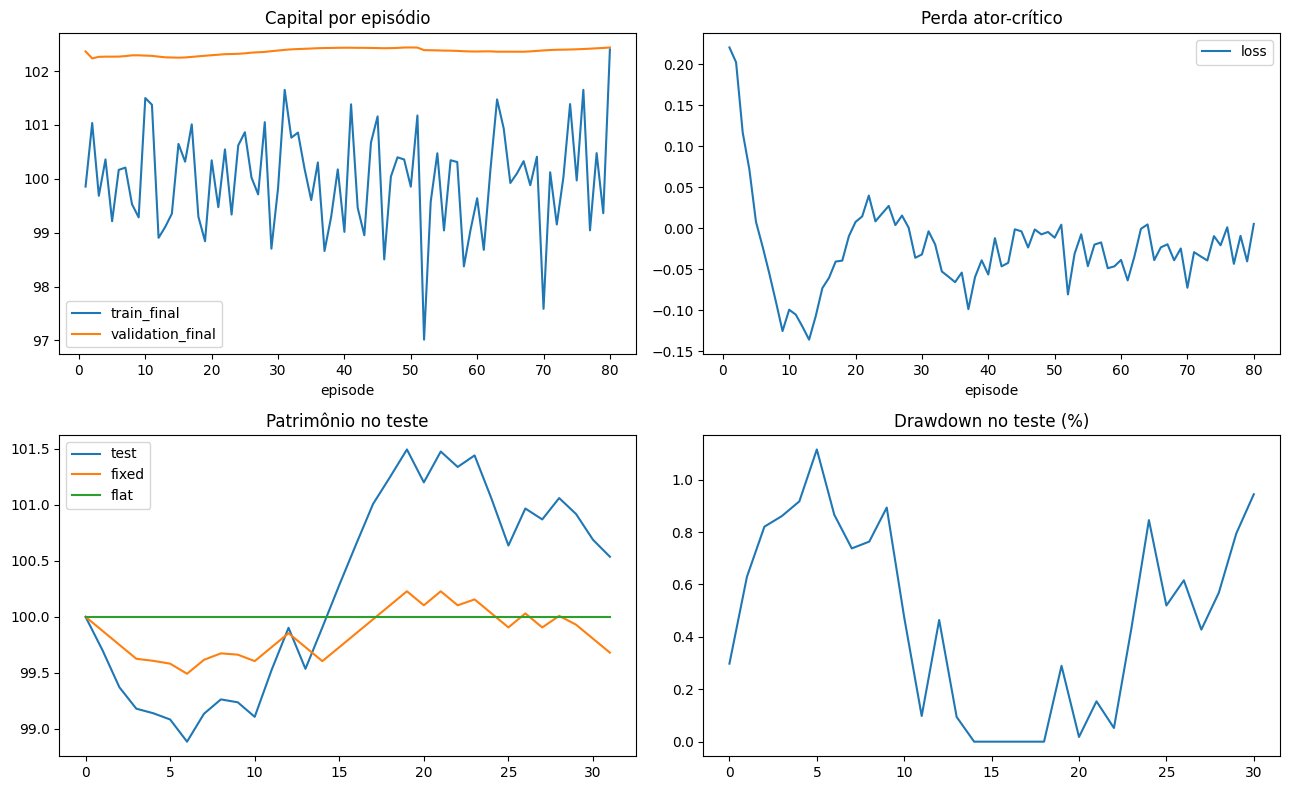

In [20]:
def capital_banner(label, initial, final):
    display(HTML(f'<div style="border:3px solid #167d9a;padding:20px;margin:12px 0">'
                 f'<h3>{label}</h3><p style="font-size:30px;font-weight:bold">'
                 f'CAPITAL INICIAL: ${initial:,.4f}<br>CAPITAL FINAL: ${final:,.4f}</p></div>'))


if MODE == "train":
    last_history = training["training_histories"][-1]
    capital_banner("TREINAMENTO — ÚLTIMO EPISÓDIO", CONFIG["initial_capital"], last_history.capital_after.iloc[-1])
    capital_banner("TESTE — POLÍTICA SELECIONADA", CONFIG["initial_capital"], evaluations["test"].capital_after.iloc[-1])
    figure, axes = plt.subplots(2, 2, figsize=(13, 8))
    progress = training["progress"]
    progress.plot(x="episode", y=["train_final", "validation_final"], ax=axes[0, 0], title="Capital por episódio")
    progress.plot(x="episode", y="loss", ax=axes[0, 1], title="Perda ator-crítico")
    for name in ("test", "fixed", "flat"):
        curve = [CONFIG["initial_capital"], *evaluations[name].capital_after.tolist()]
        axes[1, 0].plot(curve, label=name)
    axes[1, 0].set_title("Patrimônio no teste")
    axes[1, 0].legend()
    axes[1, 1].plot(evaluations["test"].drawdown.to_numpy() * 100)
    axes[1, 1].set_title("Drawdown no teste (%)")
    figure.tight_layout()
    plt.show()


<a id="etapa-11-parte-3"></a>

### 11.3 Cada operação e cada atualização de capital

A tabela preserva `timestamp | Position_size | Take_profit | Stop_loss | Result | Capital_atualizado`. O timestamp é o período real de execução, t+1. `Position_size` é valor monetário alocado, na unidade da banca; direção e quantidade continuam no registro detalhado. TP e SL são preços absolutos, enquanto a inferência devolve distâncias relativas. `Result` é lucro ou prejuízo líquido, e `Capital_atualizado` é o saldo cumulativo após a operação.

Cada painel contém todas as linhas, sem truncamento. Preservamos episódios de treino e validação, avaliações finais e comparadores. Decisões sem posição aparecem com resultado zero. O capital de uma linha financia a seguinte; não é um saldo a somar novamente.


In [21]:
def operations_table(history):
    return pd.DataFrame({
        "timestamp": history.execution_time,
        "Position_size": history.capital_before * history.exposure * (history.direction != 0),
        "Take_profit": history.tp,
        "Stop_loss": history.sl,
        "Result": history.net_pnl,
        "Capital_atualizado": history.capital_after,
    })


if MODE == "train":
    display(evaluations["test"].reason.value_counts().rename("ocorrências").to_frame())
    panels = []
    for label, histories in (("Treino", training["training_histories"]),
                             ("Validação", training["validation_histories"])):
        for episode, history in enumerate(histories, 1):
            table = operations_table(history).to_html(index=False, max_rows=None, max_cols=None)
            panels.append(f"<details><summary>{label} — episódio {episode}</summary>{table}</details>")
    for name, history in evaluations.items():
        table = operations_table(history).to_html(index=False, max_rows=None, max_cols=None)
        panels.append(f"<details><summary>Avaliação — {name}</summary>{table}</details>")
    display(HTML("".join(panels)))


,ocorrências
reason,
CLOSE,16
TP,10
SL,5


timestamp,Position_size,Take_profit,Stop_loss,Result,Capital_atualizado
2024-07-19,42.337796,1.108005,1.080450,-0.093212,99.906788
2024-07-22,30.113518,1.095174,1.081828,0.022140,99.928928
2024-07-23,25.804164,1.098516,1.083445,-0.097133,99.831795
2024-07-24,53.126153,1.092413,1.075426,-0.073419,99.758376
2024-07-25,21.943302,1.091355,1.079649,0.008097,99.766473
2024-07-26,52.219706,1.098121,1.073604,0.048142,99.814615
2024-07-29,69.916044,1.090008,1.078328,-0.289601,99.525014
2024-07-30,56.761015,1.086267,1.077316,-0.031473,99.493542
2024-07-31,34.051290,1.093969,1.071170,0.028334,99.521876
2024-08-01,60.757634,1.089248,1.078436,-0.239295,99.282580


<a id="etapa-11-parte-4"></a>

### 11.4 Registros salvos e interpretação responsável

O checkpoint foi salvo na etapa 10, antes do monitoramento, e contém tudo para inferência. Agora gravamos históricos, tabelas, métricas, evolução e figura. O manifesto registra hashes dos datasets, períodos utilizados, exclusões e critério de seleção, permitindo identificar os insumos que produziram o resultado.

Soma de recompensas não é lucro monetário, e drawdown não esgota os riscos de mercado. Custos zero, histórico pequeno, vendas sintéticas e causalidade upstream ainda não auditada limitam as conclusões. Os resultados avaliam um protótipo verificável. Para reutilizar a política, carregue `agent_checkpoint.pt` e forneça a observação à interface da etapa 10. Nenhum CSV de monitoramento ou módulo Python auxiliar é necessário.


In [22]:
if MODE == "train":
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    training["progress"].to_csv(ARTIFACT_DIR / "training_progress.csv", index=False)
    summary.to_csv(ARTIFACT_DIR / "evaluation_summary.csv")
    for name, history in evaluations.items():
        history.to_csv(ARTIFACT_DIR / f"{name}_trades.csv", index=False)
        operations_table(history).to_csv(ARTIFACT_DIR / f"{name}_operations.csv", index=False)
    for name, histories in (("training", training["training_histories"]),
                            ("validation", training["validation_histories"])):
        pd.concat(histories, ignore_index=True).to_csv(ARTIFACT_DIR / f"all_{name}_trades.csv", index=False)
        tables = [operations_table(history).assign(episode=episode)
                  for episode, history in enumerate(histories, 1)]
        pd.concat(tables, ignore_index=True).to_csv(ARTIFACT_DIR / f"all_{name}_operations.csv", index=False)
    last_history.to_csv(ARTIFACT_DIR / "last_training_episode_trades.csv", index=False)
    operations_table(last_history).to_csv(ARTIFACT_DIR / "last_training_episode_operations.csv", index=False)
    figure.savefig(ARTIFACT_DIR / "monitoramento.png", dpi=150)
    manifest = {
        "config": CONFIG, "best_episode": training["best_episode"],
        "selection": "maximum_validation_reward_sum", "checkpoint": CHECKPOINT_PATH.name,
        "feature_columns": agent["feature_columns"],
        "inputs": {str(path.relative_to(PROJECT_ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                   for path in (STATE_PATH, RAW_PATH)},
        "excluded": {str(t): str(row.execution_time) for t, row in excluded.iterrows()},
        "splits": {name: {"rows": len(index), "start": str(index[0]), "end": str(index[-1]),
                          "last_execution": str(market.loc[index, "execution_time"].iloc[-1])}
                   for name, index in training["indices"].items()},
    }
    (ARTIFACT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    print(f"Verificações mecânicas concluídas; resultados gravados em {ARTIFACT_DIR}")


Verificações mecânicas concluídas; resultados gravados em C:\projects\Libellula\notebooks\modelo_RL_gestao_banca\resultados
